In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('/Users/sachinchoudhary/Developer/ML/data/student_clustering.csv')
df.head()

,cgpa,iq
0,5.13,88
1,5.90,113
2,8.36,93
3,8.27,97
4,5.45,110


In [3]:
import matplotlib.pyplot as plt

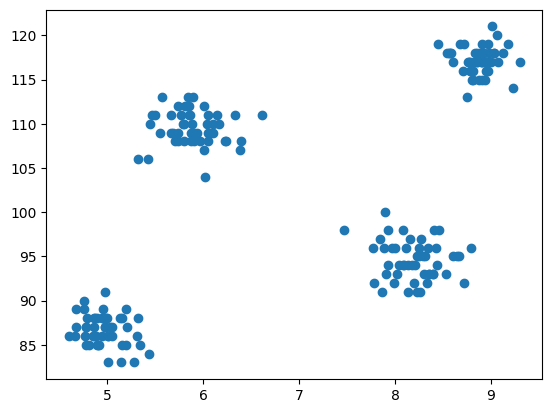

In [4]:
plt.scatter(df['cgpa'], df['iq'])

In [5]:
from sklearn.cluster import KMeans

wcss = []

for i in range(1,21):
    km = KMeans(n_clusters=i)
    km.fit(df)
    wcss.append(km.inertia_)

In [6]:
wcss

[29957.898288,
 4184.14127,
 2503.397581,
 681.96966,
 599.4812142280703,
 388.8524026875981,
 367.74677344642856,
 278.2915110145655,
 259.19139393090575,
 172.49195015473822,
 169.62225893630495,
 140.74778913836377,
 125.59398931659213,
 104.83413121011449,
 98.2185254895403,
 83.77347400337467,
 79.37345259114983,
 71.05643419386986,
 58.32907643784321,
 55.07855219432442]

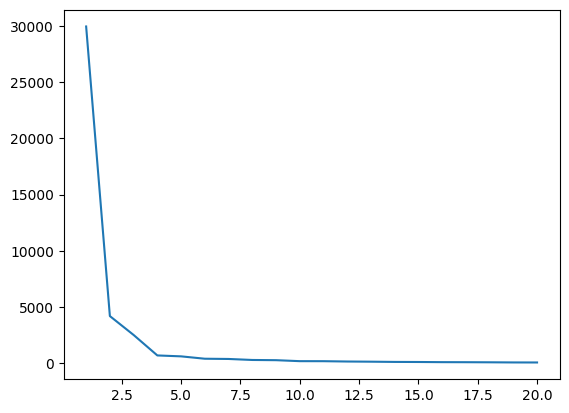

In [7]:
plt.plot(range(1,21), wcss)

In [8]:
X = df.iloc[:,:].values
km = KMeans(n_clusters=4)
y_mean = km.fit_predict(X)


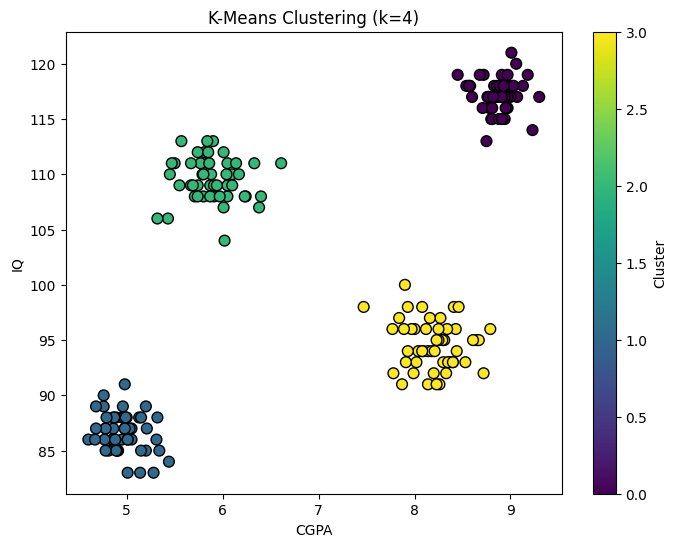

In [11]:
# Plot the clustered data points with their cluster assignments
plt.figure(figsize=(8,6))
plt.scatter(X[:, 0], X[:, 1], c=y_mean, cmap='viridis', edgecolor='k', s=60)
plt.xlabel('CGPA')
plt.ylabel('IQ')
plt.title('K-Means Clustering (k=4)')
plt.colorbar(label='Cluster')
plt.show()

# 3D

In [ ]:
from sklearn.datasets import make_blobs

In [13]:
centroid = [(-5,-5,5),(5,5,-5),(3.5,-2.5,4),(-2.5,2.5,-4)]
cluster_std = [1,1,1,1]

X,y = make_blobs(n_samples=200,cluster_std=cluster_std,centers=centroid,n_features=3,random_state=28)

In [14]:
import plotly.express as px
fig = px.scatter_3d(x=X[:,0],y=X[:,1],z=X[:,2])
fig.show()

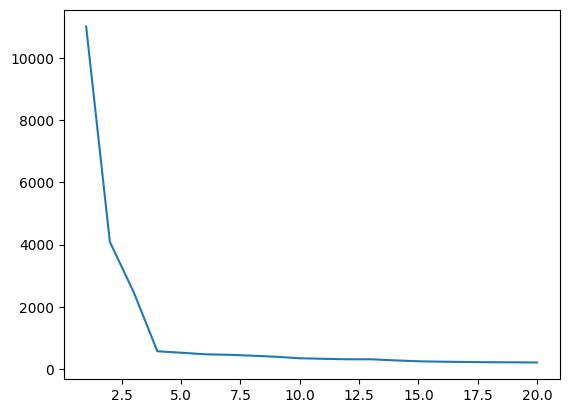

In [15]:
wcss = []

for i in range(1,21):
    km = KMeans(n_clusters=i)
    km.fit(X)
    wcss.append(km.inertia_)

plt.plot(range(1,21), wcss)

In [16]:
km = KMeans(n_clusters=4)
y_pred = km.fit_predict(X)

In [17]:
df = pd.DataFrame()

df['col1'] = X[:,0]
df['col2'] = X[:,1]
df['col3'] = X[:,2]
df['label'] = y_pred

In [19]:
fig = px.scatter_3d(df,x='col1',y='col2',z='col3',color='label')
fig.show()